# 03 — Optimizers playground: how models actually get trained

You know the update `w ← w − lr·∇L`. In practice, training a model is mostly about *making that update work*: picking
the learning rate, the batch size, the optimizer and the schedule — and recognising from a loss curve what went
wrong. This notebook is a playground: write each optimizer in a few lines, then watch them race.

**Datasets**
- 2-D toy surfaces, so you can *see* trajectories.
- *Fashion-MNIST* (Zalando, 2017): 28×28 photos of clothes, 10 classes. The model is **softmax regression** —
  logistic regression with 10 classes, the direct extension of notebook 01. Simple model, so every effect you see
  comes from the optimizer, not the architecture.

**What you will learn**
- What momentum and Adam do, geometrically, on a narrow valley and on a banana.
- The learning-rate range test: how practitioners pick a learning rate in 2 minutes.
- Reading loss curves: too small, too large, diverging, noisy.
- Batch size: noise vs number of updates.
- Learning-rate schedules: why the loss drops when the learning rate drops.

**Time:** ~2 h. Legend: 📖 read · 🔮 predict (+ `[1]`/`[2]`/`[3]`) · ✍️ your code · 🧪 explore · 🛠️ habit.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from mlj.datasets import load_fashion_mnist, FASHION_CLASSES

torch.manual_seed(0)
plt.rcParams["figure.figsize"] = (6, 3.5)

def check(cond, msg):
    print(("✅ " if cond else "❌ ") + msg)

## Part 1 — Write three optimizers (20 min)

Each optimizer is a function `step(x, g, state, **hyper) -> x_new` where `state` is a dict it may use to remember
things between steps (it starts empty: `{}`).

📖 The three updates:
- **SGD**: `x ← x − lr·g`
- **Momentum**: `v ← β·v + g`, then `x ← x − lr·v`. `v` is a running sum of past gradients: directions that agree
  accumulate, directions that flip sign cancel. Think of a heavy ball rolling downhill.
- **Adam**: `m ← β₁m + (1−β₁)g` (mean of gradients), `s ← β₂s + (1−β₂)g²` (mean of squared gradients),
  bias-correct `m̂ = m/(1−β₁ᵗ)`, `ŝ = s/(1−β₂ᵗ)`, then `x ← x − lr·m̂/(√ŝ + ε)`. Each coordinate gets its own step
  size: divided by the typical size of its gradient.

✍️ Fill in the three functions.

<details><summary>▶ Hint (state)</summary>

`v = state.get("v", np.zeros_like(x))` then store it back: `state["v"] = v`. For Adam keep a step counter
`state["t"]`, starting at 1 on the first call.
</details>

In [2]:
def sgd(x, g, state, lr):
    return x - lr * g

def momentum(x, g, state, lr, beta=0.9):
    v = beta * state.get("v", np.zeros_like(x)) + g
    state["v"] = v
    return x - lr * v

def adam(x, g, state, lr, b1=0.9, b2=0.999, eps=1e-8):
    t = state.get("t", 0) + 1
    m = b1 * state.get("m", np.zeros_like(x)) + (1 - b1) * g
    s = b2 * state.get("s", np.zeros_like(x)) + (1 - b2) * g ** 2
    state.update(t=t, m=m, s=s)
    m_hat, s_hat = m / (1 - b1 ** t), s / (1 - b2 ** t)
    return x - lr * m_hat / (np.sqrt(s_hat) + eps)

# check against torch.optim on f(x) = sum(x^4) for 20 steps
def compare(mine, make_torch, **hyper):
    x = np.array([1.0, -2.0]); st = {}
    xt = torch.tensor(x.copy(), requires_grad=True); opt = make_torch([xt])
    for _ in range(20):
        x = mine(x, 4 * x ** 3, st, **hyper)
        opt.zero_grad(); (xt ** 4).sum().backward(); opt.step()
    return np.allclose(x, xt.detach().numpy(), atol=1e-6)

check(compare(sgd, lambda p: torch.optim.SGD(p, lr=0.01), lr=0.01), "SGD matches torch")
check(compare(momentum, lambda p: torch.optim.SGD(p, lr=0.01, momentum=0.9), lr=0.01), "momentum matches torch")
check(compare(adam, lambda p: torch.optim.Adam(p, lr=0.1), lr=0.1), "Adam matches torch")

✅ SGD matches torch
✅ momentum matches torch
✅ Adam matches torch


## Part 2 — The race (25 min)

Two surfaces:
- **Narrow valley** `f = ½(x² + 100y²)`: 100× more curved in `y` than in `x` — like unscaled features in notebook 01.
- **Rosenbrock banana** `f = (1 − x)² + 100(y − x²)²`: the minimum `(1, 1)` sits at the end of a long, curved, flat
  valley. A classic torture test.

In [3]:
surfaces = {
    "valley": (lambda x, y: 0.5 * (x ** 2 + 100 * y ** 2), np.array([-9.0, 1.0]), (-10, 10, -1.5, 1.5)),
    "banana": (lambda x, y: (1 - x) ** 2 + 100 * (y - x ** 2) ** 2, np.array([-1.5, 2.0]), (-2, 2, -1, 3)),
}

def grad(f, p):
    t = torch.tensor(p, requires_grad=True)
    f(t[0], t[1]).backward()
    return t.grad.numpy()

def run(step_fn, surface, n_steps=300, **hyper):
    f, x, _ = surfaces[surface]
    x, st, path = x.copy(), {}, [x.copy()]
    for _ in range(n_steps):
        x = step_fn(x, grad(f, x), st, **hyper)
        path.append(x.copy())
        if not np.all(np.isfinite(x)) or np.abs(x).max() > 1e3:
            break
    return np.array(path)

def race(surface, contenders, n_steps=300):
    f, _, (x0, x1, y0, y1) = surfaces[surface]
    X, Y = np.meshgrid(np.linspace(x0, x1, 300), np.linspace(y0, y1, 300))
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].contour(X, Y, f(X, Y), levels=np.logspace(-2, 3.5, 25), cmap="Greys", linewidths=0.6)
    for name, (fn, hyper) in contenders.items():
        p = run(fn, surface, n_steps, **hyper)
        ax[0].plot(p[:, 0], p[:, 1], ".-", ms=2, lw=1, label=name)
        ax[1].semilogy([f(*q) + 1e-12 for q in p], label=name)
    ax[0].set_xlim(x0, x1); ax[0].set_ylim(y0, y1); ax[0].legend(fontsize=8)
    ax[1].set_xlabel("step"); ax[1].set_ylabel("f"); ax[1].legend(fontsize=8); plt.show()

🔮 On the valley: SGD with the largest stable learning rate — will it zig-zag, crawl, or both? Will momentum help? Will
Adam look different from the other two, and why?

> Prediction:

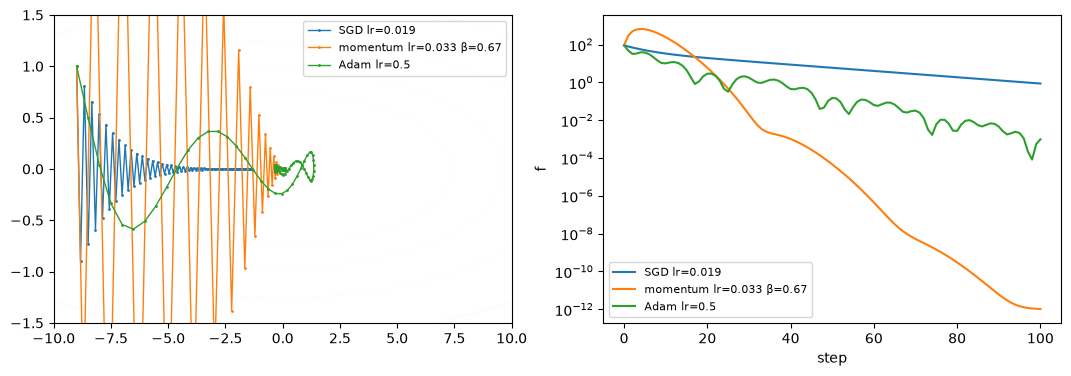

In [4]:
race("valley", {
    "SGD lr=0.019": (sgd, dict(lr=0.019)),
    "momentum lr=0.033 β=0.67": (momentum, dict(lr=0.033, beta=0.67)),
    "Adam lr=0.5": (adam, dict(lr=0.5)),
}, n_steps=100)

📖 SGD's learning rate is capped by the steep direction (above `lr = 2/100 = 0.02` it diverges along `y`), so along
the flat `x` direction each step only removes 2 % of the distance: it crawls. Momentum accumulates the consistent `x`
gradient and cancels the oscillating `y` one (its settings here are the theoretical optimum for this quadratic — in
real life you never know them). Adam rescales each coordinate by its own gradient size, so its step is not capped by
the steep direction and it closes the distance along `x` quickly — then, with a constant learning rate, it keeps bouncing around it instead of landing (remember this for
Part 6).

🧪 **Explore.** Set SGD to `lr=0.021`. Give momentum the "default" `beta=0.9`. Then race on the **banana**: find, for
each optimizer, a learning rate (and `beta` for momentum) that gets to `f < 1e-3` within 1000 steps. Note the best
settings and how narrow the working range was — you are doing hyperparameter search by hand.

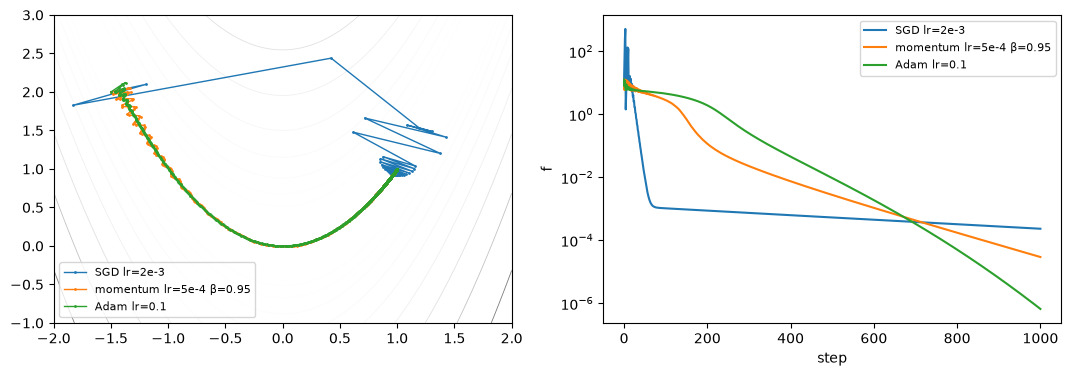

In [5]:
race("banana", {
    "SGD lr=2e-3": (sgd, dict(lr=2e-3)),
    "momentum lr=5e-4 β=0.95": (momentum, dict(lr=5e-4, beta=0.95)),
    "Adam lr=0.1": (adam, dict(lr=0.1)),
}, n_steps=1000)

> Best settings I found:

## Part 3 — A real model: softmax regression on Fashion-MNIST (15 min)

From now on we use `torch.optim` (you just showed yours match it) on a real training loop.

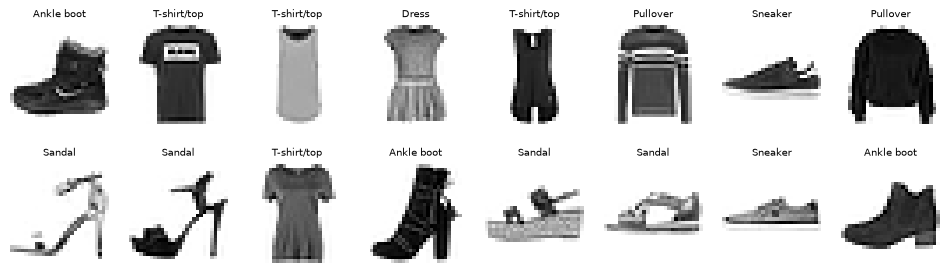

torch.Size([12000, 784]) | classes: [1122, 1220, 1201, 1212, 1181, 1204, 1244, 1192, 1195, 1229]


In [6]:
Xtr, ytr, Xte, yte = load_fashion_mnist()
fig, axes = plt.subplots(2, 8, figsize=(12, 3.3))
for ax, i in zip(axes.flat, range(16)):
    ax.imshow(Xtr[i].reshape(28, 28), cmap="gray_r"); ax.set_title(FASHION_CLASSES[ytr[i]], fontsize=7); ax.axis("off")
plt.show()

# 12k images for training, 3k for validation: small enough that every run takes seconds on CPU
X = torch.tensor(Xtr[:15000], dtype=torch.float32) / 255.0
y = torch.tensor(ytr[:15000])
X = (X - X[:12000].mean()) / X[:12000].std()
X_tr, y_tr, X_va, y_va = X[:12000], y[:12000], X[12000:], y[12000:]
print(X_tr.shape, "| classes:", torch.bincount(y_tr).tolist())

✍️ Write the generic training loop. It is the same loop you will write for every PyTorch model, including the
transformer in notebook 05 — learn it by heart: **zero_grad → forward → loss → backward → step**.

In [7]:
def train(opt_name="adam", lr=1e-3, batch_size=128, epochs=3, schedule=None, seed=0, log_every=10):
    torch.manual_seed(seed)
    model = nn.Linear(784, 10)                   # softmax regression: logits = XW + b
    opt = {"sgd": lambda p: torch.optim.SGD(p, lr=lr),
           "momentum": lambda p: torch.optim.SGD(p, lr=lr, momentum=0.9),
           "adam": lambda p: torch.optim.Adam(p, lr=lr)}[opt_name](model.parameters())
    n_steps = epochs * (len(X_tr) // batch_size)
    sched = schedule(opt, n_steps) if schedule else None
    losses, step = [], 0
    for _ in range(epochs):
        perm = torch.randperm(len(X_tr))
        for i in range(0, len(X_tr) - batch_size + 1, batch_size):
            idx = perm[i:i + batch_size]
            opt.zero_grad()
            loss = F.cross_entropy(model(X_tr[idx]), y_tr[idx])
            loss.backward()
            opt.step()
            if sched: sched.step()
            if step % log_every == 0:
                losses.append((step, loss.item()))
            step += 1
            if not np.isfinite(loss.item()):
                return model, np.array(losses)
    return model, np.array(losses)

def val_acc(model):
    with torch.no_grad():
        return (model(X_va).argmax(1) == y_va).float().mean().item()

model, L = train()
print(f"val accuracy: {val_acc(model):.3f}")
check(val_acc(model) > 0.80, "softmax regression > 80 % on Fashion-MNIST")

val accuracy: 0.823
✅ softmax regression > 80 % on Fashion-MNIST


🛠️ **Habit: know what loss to expect at step 0.** With 10 classes and a random small init, the model predicts ~uniform
probabilities, so the first loss should be close to `log 10 ≈ 2.30`. If your first loss is 50, something is wrong
before training even starts (bad init, unnormalised inputs, wrong labels).

In [8]:
print(f"first logged loss: {L[0, 1]:.3f}   vs log(10) = {np.log(10):.3f}")

first logged loss: 2.443   vs log(10) = 2.303


## Part 4 — Picking the learning rate: the range test (20 min)

📖 **LR range test** (Smith, 2015): train for a few hundred steps while increasing the learning rate exponentially,
from `1e-6` to `10`. Plot loss vs learning rate. The loss is flat (lr too small), then drops (good zone), then
explodes (too large). A good learning rate is roughly **10× below where the loss is lowest**, i.e. in the steepest
part of the descent.

✍️ Implement it: same loop, but before each step set `g["lr"]` for every `g in opt.param_groups`.

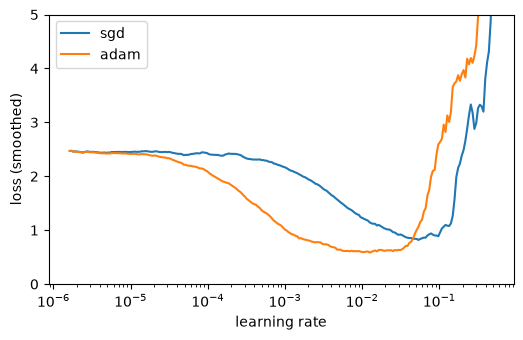

In [9]:
def lr_range_test(opt_name, lr_min=1e-6, lr_max=10.0, n_steps=300, batch_size=128):
    torch.manual_seed(0)
    model = nn.Linear(784, 10)
    opt = (torch.optim.Adam if opt_name == "adam" else torch.optim.SGD)(model.parameters(), lr=lr_min)
    lrs = np.geomspace(lr_min, lr_max, n_steps)
    losses = []
    for lr in lrs:
        idx = torch.randint(0, len(X_tr), (batch_size,))
        for g in opt.param_groups:
            g["lr"] = lr
        opt.zero_grad()
        loss = F.cross_entropy(model(X_tr[idx]), y_tr[idx])
        loss.backward()
        opt.step()
        losses.append(loss.item())
        if not np.isfinite(loss.item()) or loss.item() > 4 * losses[0]:
            break
    return lrs[:len(losses)], np.array(losses)

for name in ["sgd", "adam"]:
    lrs, ls = lr_range_test(name)
    smooth = np.convolve(ls, np.ones(10) / 10, mode="valid")
    plt.semilogx(lrs[9:], smooth, label=name)
plt.xlabel("learning rate"); plt.ylabel("loss (smoothed)"); plt.ylim(0, 5); plt.legend(); plt.show()

🔮 From the plot, write down a learning rate for SGD and one for Adam.

> Prediction:

🧪 **Explore.** Train for 3 epochs with three learning rates for one optimizer: your pick, 30× smaller, 30× larger.
Plot the three loss curves on the same axes. Name each failure mode you see: *slow*, *noisy plateau*, *diverging*.

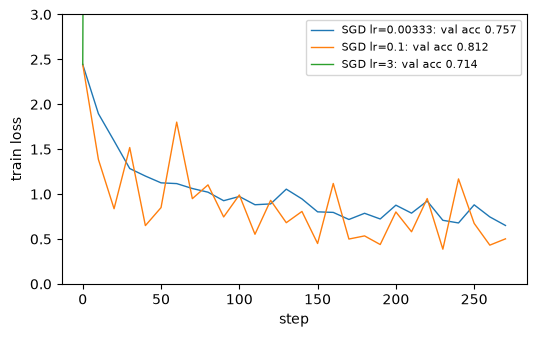

In [10]:
for lr in [0.1 / 30, 0.1, 0.1 * 30]:
    m, L = train("sgd", lr=lr)
    plt.plot(L[:, 0], L[:, 1], label=f"SGD lr={lr:.3g}: val acc {val_acc(m):.3f}", lw=1)
plt.ylim(0, 3); plt.xlabel("step"); plt.ylabel("train loss"); plt.legend(fontsize=8); plt.show()

> What I see:

## Part 5 — Batch size (15 min)

🔮 Same number of **epochs** (3), Adam at `lr = 1e-3`: batch 16 vs 128 vs 2048. Which ends with the lowest loss? Which
is fastest in wall-clock time? Which is noisiest?

> Prediction:

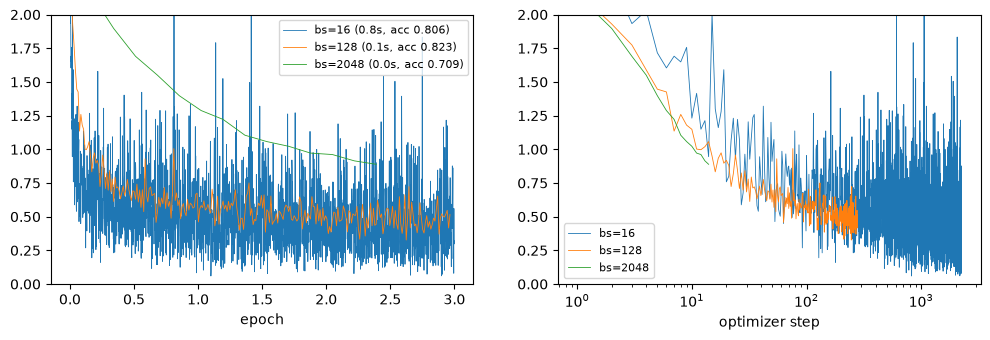

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for bs in [16, 128, 2048]:
    t0 = time.time()
    m, L = train("adam", lr=1e-3, batch_size=bs, log_every=1)
    dt = time.time() - t0
    epochs_axis = L[:, 0] * bs / len(X_tr)
    ax[0].plot(epochs_axis, L[:, 1], lw=0.6, label=f"bs={bs} ({dt:.1f}s, acc {val_acc(m):.3f})")
    ax[1].plot(L[:, 0], L[:, 1], lw=0.6, label=f"bs={bs}")
ax[0].set_xlabel("epoch"); ax[1].set_xlabel("optimizer step"); ax[1].set_xscale("log")
for a in ax: a.set_ylim(0, 2); a.legend(fontsize=8)
plt.show()

📖 A mini-batch gradient is a noisy estimate of the full gradient; its noise shrinks like `1/√batch`. Small batches:
many cheap, noisy updates per epoch. Large batches: few accurate updates, better hardware use. At a fixed number of
epochs, large batches often lose simply because they took far fewer steps.

🧪 **Explore.** Give batch 2048 a fair chance: multiply its learning rate by 16 (the *linear scaling rule*: batch
×16 → lr ×16) and compare again. Does it close the gap?

> What I see:

## Part 6 — Learning-rate schedules (10 min)

Noisy SGD/Adam bounces around the minimum at a distance proportional to the learning rate. Lowering the learning rate
at the end lets it settle. Transformers use **linear warmup + cosine decay** (you will reuse it in notebook 05).

✍️ Write `warmup_cosine(step)`, a multiplier of the base lr: linear from ~0 to 1 over `warmup` steps, then cosine from
1 down to 0 at `total`. `torch.optim.lr_scheduler.LambdaLR` applies it.

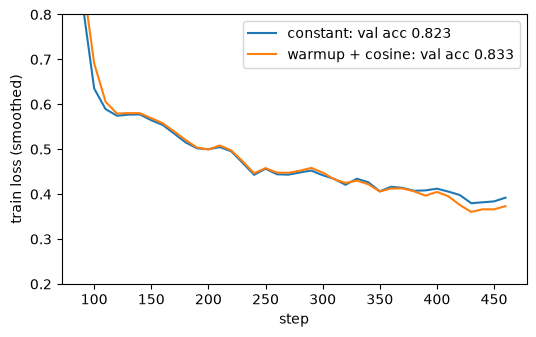

In [12]:
def make_warmup_cosine(warmup_frac=0.05):
    def schedule(opt, total):
        warmup = max(1, int(warmup_frac * total))
        def mult(step):
            if step < warmup:
                return (step + 1) / warmup
            progress = (step - warmup) / max(1, total - warmup)
            return 0.5 * (1 + np.cos(np.pi * progress))
        return torch.optim.lr_scheduler.LambdaLR(opt, mult)
    return schedule

m_const, L_const = train("adam", lr=3e-3, epochs=5)
m_cos, L_cos = train("adam", lr=3e-3, epochs=5, schedule=make_warmup_cosine())
k = 10
for L_, name, m in [(L_const, "constant", m_const), (L_cos, "warmup + cosine", m_cos)]:
    plt.plot(L_[k - 1:, 0], np.convolve(L_[:, 1], np.ones(k) / k, "valid"), label=f"{name}: val acc {val_acc(m):.3f}")
plt.xlabel("step"); plt.ylabel("train loss (smoothed)"); plt.ylim(0.2, 0.8); plt.legend(); plt.show()

Watch the end of the cosine curve: the loss keeps dropping as the learning rate goes to zero. That last drop is the
model settling into the minimum instead of bouncing around it.

## Part 7 — Cheat sheet you just earned

🛠️ What to do on a new project:
1. Check the step-0 loss against its expected value (`log C` for classification).
2. Start with **Adam(W)**, `lr = 1e-3` (3e-4 for transformers). Run a range test if the loss misbehaves.
3. Loss goes NaN or up → learning rate too high (or a bug: inputs not normalised, log of 0).
   Loss flat → too low, or gradients not flowing (forgot `zero_grad`, forgot `step`, detached tensor).
4. Use the largest batch that fits, scale the learning rate with it, add warmup + cosine for long runs.
5. Change **one** thing at a time and write down what you expected before running.

🧪 *Optional:* look at the learned weights. Reshape `m_cos.weight[c]` to 28×28 for each class `c` and plot them.
Softmax regression is a template matcher — can you recognise the trousers?

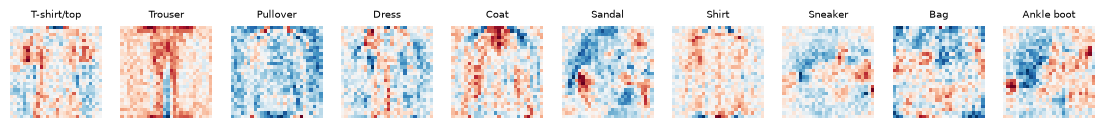

In [13]:
fig, axes = plt.subplots(1, 10, figsize=(14, 1.8))
for c, ax in enumerate(axes):
    ax.imshow(m_cos.weight[c].detach().reshape(28, 28), cmap="RdBu_r"); ax.set_title(FASHION_CLASSES[c], fontsize=7); ax.axis("off")
plt.show()

## Debrief → `learning/LOG.md`

1. Momentum and Adam updates from memory; what each fixes on the narrow valley.
2. How you pick a learning rate on a new problem, in three sentences.
3. Batch size: what changes with it, and the scaling rule.
4. Why the loss drops at the end of a cosine schedule.
5. **Still shaky:** ✍️ cells that took more than two tries, 🔮 tagged `[2]`/`[3]` that were wrong.